# Explore the SCANNED full pipeline

End-to-end on one or many pages of a scanned Indic + English PDF. Set `PAGES = -1` 
for the whole PDF, or a list like `[0, 2, 5]` for specific pages (0-indexed).

Flow per page:

```
Step 1  preprocessing      (orient → deskew → crop borders → dotted-line removal)
Step 2  OCR + bbox         (Bodhan indic-ocr → Gemini fallback)
Step 3  dedup + ordering   (geometric dedup → draw labels → LLM re-order)
Step 4  DOCX               (utils.docx_builder.build_docx on the ordered page)
```

The ordering LLM takes a *labeled* page image (every box drawn with its id) plus a
JSON list of the blocks. Cheap VLMs can do this well when the labels are clean —
nemotron is tried first, Gemini is the fallback.

Overlap handling:
- **Containment / high-IoU duplicates** → dropped geometrically with an info-aware
  comparator (text-bearing or picture-type wins over empty).
- **Partial-overlap text duplicates** that Bodhan sometimes returns (coarse box +
  finer sub-boxes with overlapping text) → the ordering LLM is told to drop them.
  Blocks it drops appear in `dropped` and never reach the DOCX.

Place next to `main.py`.

In [54]:
import base64, io, json, os, re, sys, time
from pathlib import Path

import cv2
import numpy as np
import pymupdf
import requests
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageDraw, ImageFont

sys.path.insert(0, ".")

# ── config ──
PDF_PATH   = Path("pdf/eng_qp_scanned.pdf")
PAGES      = -1         # -1 for all pages, or a list of 0-indexed numbers e.g. [0, 2, 5]
VIZ_PAGES  = None       # pages to plot (None = first processed page only; [] = none; or a list)
DPI        = 200

OUT_DIR    = Path("explore_out_full")
CROP_DIR   = OUT_DIR / "crops"
PAGE_DIR   = OUT_DIR / "pages"
for d in (OUT_DIR, CROP_DIR, PAGE_DIR):
    d.mkdir(parents=True, exist_ok=True)

BODHAN_KEY     = os.environ.get("BODHAN_OCR_API_KEY")
OPENROUTER_KEY = os.environ.get("OPENROUTER_API_KEY")

# Open the PDF once and resolve which pages to process.
doc  = pymupdf.open(PDF_PATH)
stem = PDF_PATH.stem
total = len(doc)
page_indices = list(range(total)) if PAGES == -1 else [p for p in PAGES if 0 <= p < total]
if not page_indices:
    raise ValueError(f"no valid pages in PAGES={PAGES} for a {total}-page PDF")
if VIZ_PAGES is None:
    VIZ_PAGES = page_indices[:1]      # just the first processed page by default
VIZ_PAGES = set(VIZ_PAGES) & set(page_indices)
print(f"{PDF_PATH.name}: {total} pages")
print(f"processing {len(page_indices)} page(s): {page_indices}")
print(f"plotting   {len(VIZ_PAGES)} page(s): {sorted(VIZ_PAGES)}")

# OCR engines — Bodhan primary, Gemini fallback.
OCR_FALLBACK_MODEL = "google/gemini-2.5-flash"

# Ordering engines — labeled image + JSON goes to a cheap VLM first, Gemini as safety net.
ORDER_MODELS = [
    "nvidia/nemotron-3.5-super-vl",   # cheap; works well when labels are clean
    "google/gemini-2.5-flash",        # fallback if the first errors or returns garbage
]

eng_qp_scanned.pdf: 19 pages
processing 19 page(s): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
plotting   1 page(s): [0]


## Step 1 — Preprocessing

Just `remove_dotted_lines` — long dashed answer rules make the OCR model loop
until `max_tokens` hits. Other steps from the preprocessing notebook (orientation / deskew / border crop) are available but excluded here: on reasonable
scans they cost more latency than the quality gain is worth. Add them back if you
see a specific document class that needs them.

  p1    1653×2339  ·  0.7s
  p2    1653×2339  ·  0.8s
  p3    1653×2339  ·  0.8s
  p4    2339×1653  ·  0.8s
  p5    2339×1653  ·  0.9s
  p6    2339×1653  ·  0.7s
  p7    2339×1653  ·  0.6s
  p8    1653×2339  ·  0.6s
  p9    1653×2339  ·  0.8s
  p10   1653×2339  ·  0.8s
  p11   1653×2339  ·  0.7s
  p12   2339×1653  ·  0.6s
  p13   2339×1653  ·  0.7s
  p14   1653×2339  ·  0.7s
  p15   1653×2339  ·  0.6s
  p16   1653×2339  ·  0.6s
  p17   1653×2339  ·  0.6s
  p18   2339×1653  ·  0.6s
  p19   2339×1653  ·  0.6s

preprocessed 19 page(s). Images saved to explore_out_full\pages/


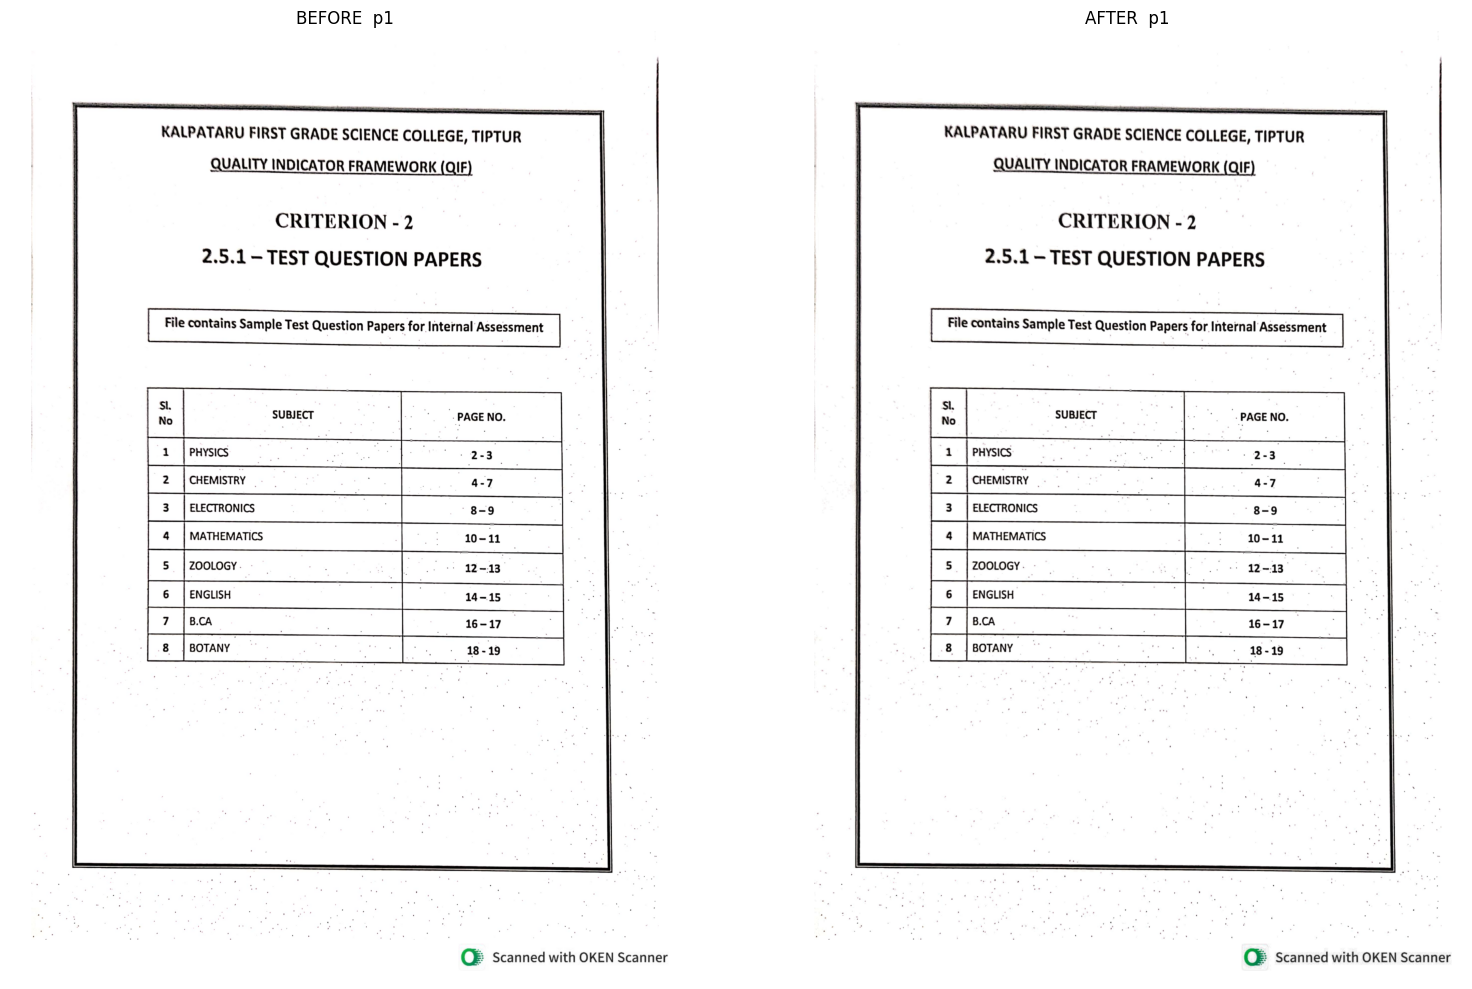

In [55]:
# # ─── dotted-line removal ───────────────────────────────────────────────────
# # Long dashed answer rules (.......) can make the OCR model loop until it
# # hits max_tokens on blank regions. Only the dot pixels are erased, so
# # neighbouring text is left intact.
# def remove_dotted_lines(bgr, min_len=200, max_dot=9, min_dots=12):
#     """Erase dotted/dashed answer lines so OCR doesn't loop on them.
#     Vectorised version — handles noisy scans with 50k+ components in sub-second time."""
#     gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
#     bw = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
#                                cv2.THRESH_BINARY_INV, 31, 15)

#     # 1) classify every connected component in one vectorised pass
#     n, lab, stats, _ = cv2.connectedComponentsWithStats(bw, 8)
#     widths  = stats[:, cv2.CC_STAT_WIDTH]
#     heights = stats[:, cv2.CC_STAT_HEIGHT]
#     areas   = stats[:, cv2.CC_STAT_AREA]
#     is_dot  = (widths <= max_dot) & (heights <= max_dot) & (areas >= 3)
#     is_dot[0] = False                                 # background label is never a dot

#     # 2) paint only the dot pixels — one array lookup across the whole image
#     lut  = (is_dot.astype(np.uint8)) * 255
#     dots = lut[lab]

#     # 3-5) same as before: chain into strips, filter, erase
#     chain = cv2.dilate(dots, cv2.getStructuringElement(cv2.MORPH_RECT, (17, 3)))
#     cnts, _ = cv2.findContours(chain, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
#     box_mask = np.zeros(gray.shape, np.uint8)
#     found = 0
#     for c in cnts:
#         (cx, cy), (rw, rh), ang = cv2.minAreaRect(c)
#         if max(rw, rh) < min_len or min(rw, rh) > 22:
#             continue
#         x, y, w, h = cv2.boundingRect(c)
#         if (dots[y:y + h, x:x + w] > 0).sum() < min_dots * 3:
#             continue
#         box = cv2.boxPoints(((cx, cy), (rw, rh + 4), ang)).astype(np.int32)
#         cv2.fillPoly(box_mask, [box], 255)
#         found += 1
#     mask = cv2.dilate(cv2.bitwise_and(dots, box_mask), np.ones((3, 3), np.uint8))
#     out = bgr.copy()
#     out[mask > 0] = (255, 255, 255)
#     return out, found


# # ─── apply per page ────────────────────────────────────────────────────────
# preprocessed = {}   # pno -> cleaned BGR image sent to the OCR engine
# raw_images   = {}   # pno -> original rendered image (kept only for BEFORE/AFTER plots)

# for pno in page_indices:
#     pix = doc[pno].get_pixmap(dpi=DPI, alpha=False)
#     raw = cv2.imdecode(np.frombuffer(pix.tobytes("png"), np.uint8), cv2.IMREAD_COLOR)
#     img, n_dots = remove_dotted_lines(raw)
#     print(f"  p{pno+1:<3}  {img.shape[1]}×{img.shape[0]}  ·  {n_dots} dotted strip(s) erased")
#     preprocessed[pno] = img
#     if pno in VIZ_PAGES:
#         raw_images[pno] = raw
#     cv2.imwrite(str(PAGE_DIR / f"{stem}_p{pno+1}_sent.png"), img)

# print(f"\npreprocessed {len(preprocessed)} page(s). Images saved to {PAGE_DIR}/")

# # BEFORE/AFTER for the visualised pages only (so a 50-page run doesn't make 50 plots).
# for pno in sorted(VIZ_PAGES):
#     fig, ax = plt.subplots(1, 2, figsize=(16, 10))
#     ax[0].imshow(cv2.cvtColor(raw_images[pno], cv2.COLOR_BGR2RGB))
#     ax[0].set_title(f"BEFORE  p{pno+1}"); ax[0].axis("off")
#     ax[1].imshow(cv2.cvtColor(preprocessed[pno], cv2.COLOR_BGR2RGB))
#     ax[1].set_title(f"AFTER  p{pno+1}"); ax[1].axis("off")
#     plt.tight_layout(); plt.show()

# ─── preprocessing: illumination normalise + CLAHE ───────────────────────
# Only tone/contrast — the "C_faded_scan" pipeline minus geometry steps.
#
# illumination_normalize  → flattens uneven lighting (scanner strip-light
#                           fall-off, shadows, phone glare). Preserves colour.
# clahe                   → local contrast equalisation on the L channel of LAB.
#
# No orient / deskew / crop (those changed image dimensions and may have
# tripped Bodhan's 400). No dot removal (that deleted fill-in-blank dots).
# Both ops are channel-independent / LAB-based → work on BGR directly.

def _odd(k):
    k = int(k)
    return k if k % 2 else k + 1

def illumination_normalize(bgr, kernel_frac=1/30):
    """Divide each channel by a smoothed background estimate. Keeps colour."""
    k = _odd(max(31, int(max(bgr.shape[:2]) * kernel_frac)))
    out = []
    for ch in cv2.split(bgr):
        bg = cv2.medianBlur(cv2.dilate(ch, np.ones((7, 7), np.uint8)), k)
        out.append(cv2.divide(ch, bg, scale=255))
    return cv2.merge(out)

def clahe(bgr, clip=2.0, tile=8):
    """Local contrast-limited histogram equalisation on the L channel of LAB."""
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)

# ─── apply per page ────────────────────────────────────────────────────────
preprocessed = {}
raw_images   = {}

for pno in page_indices:
    t0 = time.time()
    pix = doc[pno].get_pixmap(dpi=DPI, alpha=False)
    raw = cv2.imdecode(np.frombuffer(pix.tobytes("png"), np.uint8), cv2.IMREAD_COLOR)
    img = illumination_normalize(raw)
    img = clahe(img, clip=3.0)
    print(f"  p{pno+1:<3}  {raw.shape[1]}×{raw.shape[0]}  ·  {time.time()-t0:.1f}s")
    preprocessed[pno] = img
    if pno in VIZ_PAGES:
        raw_images[pno] = raw
    cv2.imwrite(str(PAGE_DIR / f"{stem}_p{pno+1}_sent.png"), img)

print(f"\npreprocessed {len(preprocessed)} page(s). Images saved to {PAGE_DIR}/")

for pno in sorted(VIZ_PAGES):
    fig, ax = plt.subplots(1, 2, figsize=(16, 10))
    ax[0].imshow(cv2.cvtColor(raw_images[pno], cv2.COLOR_BGR2RGB))
    ax[0].set_title(f"BEFORE  p{pno+1}"); ax[0].axis("off")
    ax[1].imshow(cv2.cvtColor(preprocessed[pno], cv2.COLOR_BGR2RGB))
    ax[1].set_title(f"AFTER  p{pno+1}"); ax[1].axis("off")
    plt.tight_layout(); plt.show()

## Step 2 — OCR with Bodhan + Gemini fallback

Bodhan `indic-ocr` is the primary engine (precise bboxes, strong on Indic +
handwriting). On any failure (`RemoteDisconnected`, 429, 5xx, auth, bad response),
the fallback asks Gemini to return the **same JSON shape** so downstream code
doesn't branch. VLM bboxes are approximate — fine for ordering, not for crops.

In [56]:
BODHAN_URL     = "https://api.bodhan.ai/v1/chat/completions"
OPENROUTER_URL = "https://openrouter.ai/api/v1/chat/completions"

def _b64_png(bgr):
    return base64.b64encode(cv2.imencode(".png", bgr)[1].tobytes()).decode()

def _call_bodhan(bgr, api_key, max_tokens=8192):
    payload = {
        "model": "indic-ocr",
        "messages": [{"role": "user", "content": [
            {"type": "image_url",
             "image_url": {"url": f"data:image/png;base64,{_b64_png(bgr)}"}},
        ]}],
        "max_tokens": max_tokens,
    }
    r = requests.post(BODHAN_URL,
                      headers={"Authorization": f"Bearer {api_key}"},
                      json=payload, timeout=(10, 300))
    r.raise_for_status()
    data = r.json()
    if "error" in data:
        raise RuntimeError(f"bodhan: {data['error'].get('message')}")
    data["_engine"] = "bodhan/indic-ocr"
    return data


_FALLBACK_OCR_PROMPT = (
    "You are an OCR engine. Transcribe this document page faithfully.\n"
    "Return ONLY JSON (no fences, no commentary) matching this schema:\n"
    "{\n"
    '  "blocks": [\n'
    "    {\n"
    '      "order": 1,\n'
    '      "type": "Text" | "Title" | "SectionHeader" | "List" | "Caption"\n'
    '              | "Table" | "Picture" | "PageHeader" | "PageFooter" | "Footnote",\n'
    '      "bbox_norm": [x0, y0, x1, y1] in [0,1] top-left, or null if uncertain,\n'
    '      "text": "exact content, preserve Latin+Devanagari+Telugu+... scripts"\n'
    "    }\n"
    "  ]\n"
    "}\n"
    "Rules: emit in natural reading order. Picture/signature/stamp blocks get text=\"\". "
    "Render tables as GitHub-style pipe tables. Never fabricate bbox coordinates — use null.\n"
    "\n"
    "Classify these as PageFooter / PageHeader (NOT Text) — they are page furniture, "
    "not body content, and must not be joined with the body across page breaks:\n"
    "  • scanner watermarks: \"Scanned by CamScanner\", \"Scanned with OKEN Scanner\"\n"
    "  • page codes / numbers: \"1-2-103\", \"Page 5 of 10\", \"[1]\"\n"
    "  • page-turn hints: \"[P.T.O.]\", \"Please Turn Over\", \"Continued on next page\"\n"
    "  • signatures or handwritten margin marks\n"
)

def _parse_json_object(text):
    s = text.strip()
    if s.startswith("```"):
        lines = s.splitlines()
        if lines[0].startswith("```"): lines = lines[1:]
        if lines[-1].strip() == "```": lines = lines[:-1]
        s = "\n".join(lines)
    try:
        return json.loads(s)
    except json.JSONDecodeError:
        m = re.search(r"\{.*\}", s, re.S)
        return json.loads(m.group(0)) if m else {}

def _call_openrouter_ocr(bgr, api_key, model, timeout=180):
    H, W = bgr.shape[:2]
    payload = {
        "model": model, "temperature": 0,
        "messages": [{"role": "user", "content": [
            {"type": "text", "text": _FALLBACK_OCR_PROMPT},
            {"type": "image_url",
             "image_url": {"url": f"data:image/png;base64,{_b64_png(bgr)}"}},
        ]}],
    }
    r = requests.post(OPENROUTER_URL,
                      headers={"Authorization": f"Bearer {api_key}",
                               "Content-Type": "application/json"},
                      json=payload, timeout=timeout)
    r.raise_for_status()
    data = r.json()
    if "error" in data:
        raise RuntimeError(f"openrouter: {data['error']}")
    parsed = _parse_json_object(data["choices"][0]["message"]["content"])
    # Reshape into Bodhan's envelope so downstream code is unchanged.
    blocks = []
    for i, b in enumerate(parsed.get("blocks") or [], start=1):
        bn = b.get("bbox_norm")
        bbox_px = None
        if isinstance(bn, (list, tuple)) and len(bn) == 4:
            try:
                x0, y0, x1, y1 = [max(0.0, min(1.0, float(v))) for v in bn]
                bbox_px = [round(x0*W, 1), round(y0*H, 1), round(x1*W, 1), round(y1*H, 1)]
                if bbox_px[2] <= bbox_px[0] or bbox_px[3] <= bbox_px[1]:
                    bbox_px = None
            except (TypeError, ValueError):
                bbox_px = None
        blocks.append({
            "order": b.get("order", i), "label": b.get("type", "block"),
            "type":  b.get("type", "block"), "bbox_xyxy": bbox_px,
            "conf":  None, "text": b.get("text") or "",
        })
    return {
        "blocks": blocks,
        "choices": [{"message": {"content": ""}, "finish_reason": "stop", "index": 0}],
        "_engine": model,
    }

def ocr_with_fallback(bgr):
    try:
        print("  trying bodhan/indic-ocr …", flush=True)
        return _call_bodhan(bgr, BODHAN_KEY)
    except Exception as e:
        print(f"  bodhan failed: {type(e).__name__}: {str(e)[:200]}")
    if not OPENROUTER_KEY:
        raise RuntimeError("Bodhan failed and OPENROUTER_API_KEY is not set.")
    try:
        print(f"  trying fallback: {OCR_FALLBACK_MODEL} …", flush=True)
        return _call_openrouter_ocr(bgr, OPENROUTER_KEY, OCR_FALLBACK_MODEL)
    except Exception as e:
        print(f"  {OCR_FALLBACK_MODEL} failed: {type(e).__name__}: {str(e)[:200]}")
    raise RuntimeError("all OCR engines failed")

# ─── run OCR per page ──────────────────────────────────────────────────────
ocr_responses = {}      # pno -> Bodhan-shaped response (from either engine)
ocr_failures  = {}      # pno -> error message string

for pno in page_indices:
    img = preprocessed.get(pno)
    if img is None:
        continue
    print(f"\n── OCR page {pno+1}/{total} ──")
    try:
        resp = ocr_with_fallback(img)
        ocr_responses[pno] = resp
        (OUT_DIR / f"{stem}_p{pno+1}_raw.json").write_text(
            json.dumps(resp, ensure_ascii=False, indent=2), encoding="utf-8",
        )
        print(f"  → engine: {resp['_engine']}  ·  blocks: {len(resp['blocks'])}")
    except Exception as e:
        ocr_failures[pno] = str(e)
        print(f"  ALL OCR ENGINES FAILED for page {pno+1}: {e}")

print(f"\nOCR done: {len(ocr_responses)} succeeded, {len(ocr_failures)} failed")

# Peek at a visualised page's blocks so you can see what Bodhan returned.
for pno in sorted(VIZ_PAGES):
    resp = ocr_responses.get(pno)
    if not resp:
        continue
    print(f"\n── blocks for p{pno+1} ──")
    for b in sorted(resp["blocks"], key=lambda b: b.get("order", 0)):
        t = (b.get("text") or "").replace("\n", " ")[:60]
        print(f"  {b.get('order'):>3}  {b.get('type', '?'):<15}  {t!r}")


── OCR page 1/19 ──
  trying bodhan/indic-ocr …
  → engine: bodhan/indic-ocr  ·  blocks: 7

── OCR page 2/19 ──
  trying bodhan/indic-ocr …
  → engine: bodhan/indic-ocr  ·  blocks: 16

── OCR page 3/19 ──
  trying bodhan/indic-ocr …
  → engine: bodhan/indic-ocr  ·  blocks: 15

── OCR page 4/19 ──
  trying bodhan/indic-ocr …
  → engine: bodhan/indic-ocr  ·  blocks: 14

── OCR page 5/19 ──
  trying bodhan/indic-ocr …
  → engine: bodhan/indic-ocr  ·  blocks: 5

── OCR page 6/19 ──
  trying bodhan/indic-ocr …
  → engine: bodhan/indic-ocr  ·  blocks: 12

── OCR page 7/19 ──
  trying bodhan/indic-ocr …
  → engine: bodhan/indic-ocr  ·  blocks: 7

── OCR page 8/19 ──
  trying bodhan/indic-ocr …
  → engine: bodhan/indic-ocr  ·  blocks: 18

── OCR page 9/19 ──
  trying bodhan/indic-ocr …
  bodhan failed: HTTPError: 429 Client Error: Too Many Requests for url: https://api.bodhan.ai/v1/chat/completions
  trying fallback: google/gemini-2.5-flash …
  → engine: google/gemini-2.5-flash  ·  blocks: 38

## Step 3 — Dedup + LLM ordering

Three sub-steps:

1. **Geometric dedup** — info-aware comparator. A text-bearing block beats an empty
   container; among equals, bigger wins. Drops a candidate when ≥95% contained in a
   kept box, or when IoU with a kept box is ≥ 0.3. This handles the empty
   `PageHeader` / `PageFooter` containers cleanly, and clear nested duplicates.

2. **Draw labeled boxes** on a copy of the preprocessed image. Each box becomes `B0`,
   `B1`, ... with a coloured outline — this is what the ordering model sees.

3. **LLM ordering** — nemotron first (cheap), Gemini fallback. The prompt tells the
   model to drop blocks whose text duplicates another block (handles partial-overlap
   text duplicates that geometric dedup can't). It returns `{order: [...],
   dropped: [...]}` — only ids in `order` reach the DOCX.


── ordering page 1/19 ──
  dedup: 7 → kept 5, dropped 2
    dropped B0 [PageHeader] ''                                          IoU 0.34 with B1
    dropped B6 [PageFooter] ''                                          IoU 0.66 with B5
  trying ordering model: nvidia/nemotron-3.5-super-vl …
  ← layout: 'Single column layout with header blocks at the top, followed by a text block, a table, and a footer watermark at the bottom right.'  ·  order=5  dropped=0

── ordering page 2/19 ──
  dedup: 16 → kept 14, dropped 2
    dropped B0 [PageHeader] ''                                          IoU 0.31 with B5
    dropped B15 [PageFooter] ''                                          IoU 0.62 with B14
  trying ordering model: nvidia/nemotron-3.5-super-vl …
  ← layout: 'Single column exam paper with header information at the top, followed by sequential sections (Part-A, Part-B, Part-C), and a footer at the bottom right.'  ·  order=14  dropped=0

── ordering page 3/19 ──
  dedup: 15 → kept 11, droppe

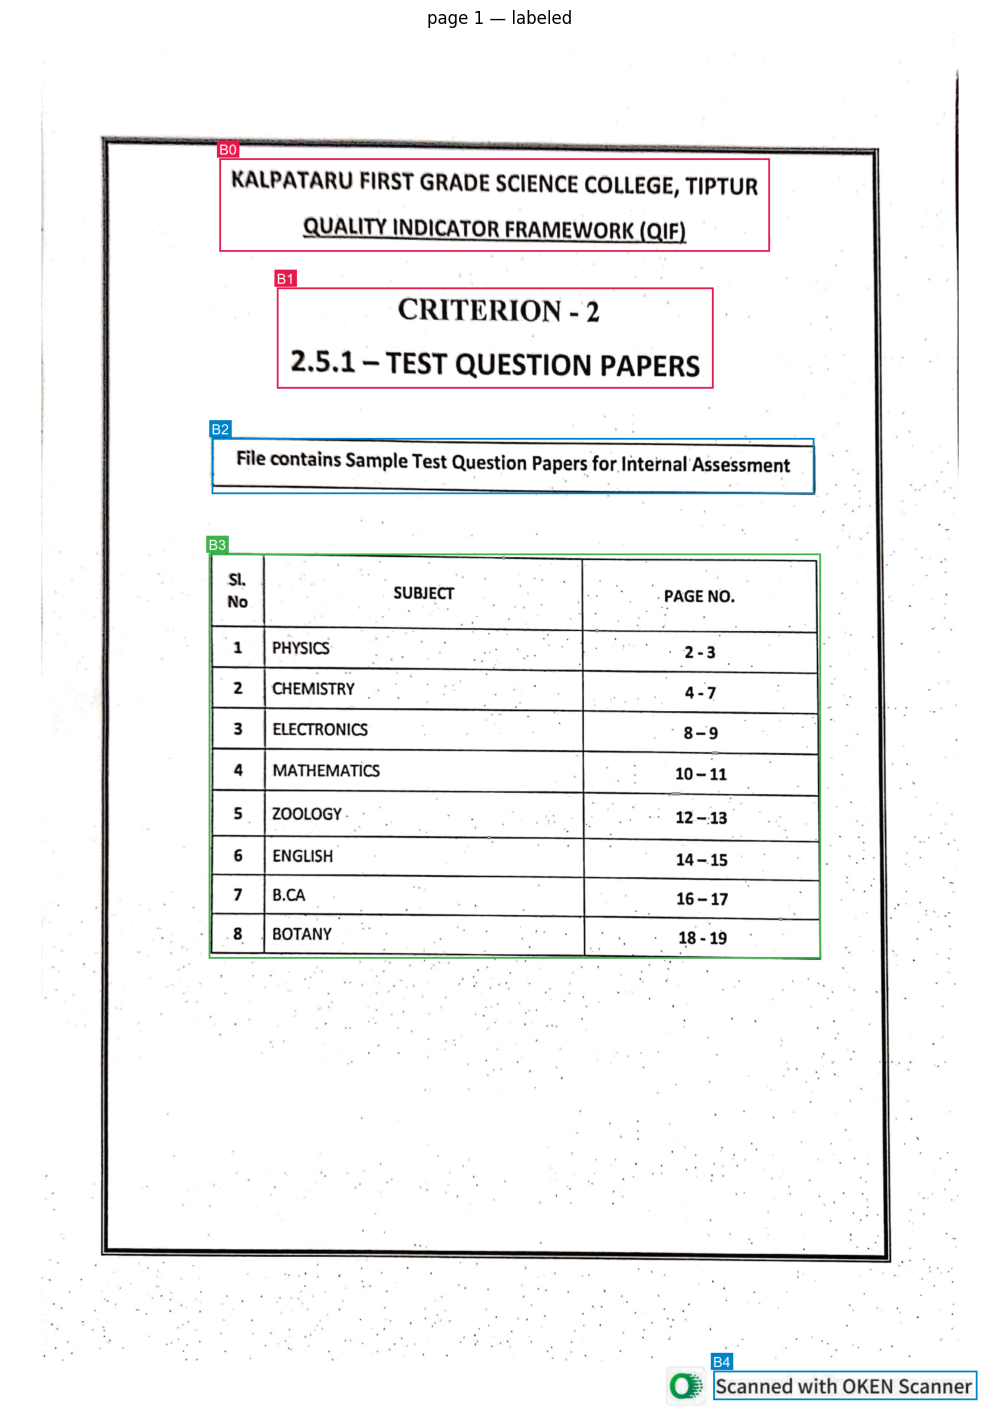

In [57]:
# ─── 3a. geometric dedup ──────────────────────────────────────────────────
_PICTURE_TYPES = {"Picture", "Chart", "Diagram", "Image", "Figure", "picture"}

def _area(b): return max(0, b[2] - b[0]) * max(0, b[3] - b[1])
def _inter(a, b):
    x0, y0 = max(a[0], b[0]), max(a[1], b[1])
    x1, y1 = min(a[2], b[2]), min(a[3], b[3])
    return max(0, x1 - x0) * max(0, y1 - y0)

def _is_informative(block):
    if (block.get("text") or "").strip(): return True
    return block.get("type") in _PICTURE_TYPES
import string

def _normalize_words(text):
    """Lowercase + strip punctuation. 'SYSTEM.' and 'system' become the same word."""
    tbl = str.maketrans('', '', string.punctuation + "।॥")
    return {w.translate(tbl).lower() for w in (text or "").split() if w.strip()}


def dedup_boxes(blocks, iou_threshold=0.3, contain_threshold=0.95, text_subsume_threshold=0.6):
    """Drop a candidate when ANY of these holds vs. a kept box:
       (1) ≥contain_threshold of its area is inside the kept box (geometric containment)
       (2) IoU ≥ iou_threshold (strong geometric overlap)
       (3) bbox overlaps at all AND ≥text_subsume_threshold of its words appear in the
           kept box (partial geometric + content subsumption — catches Bodhan's
           coarse-and-fine box pattern that pure geometry misses)
    """
    sorted_blocks = sorted(
        blocks,
        key=lambda b: (_is_informative(b), _area(b.get("bbox_xyxy") or [0,0,0,0])),
        reverse=True,
    )
    kept, removed = [], []
    for c in sorted_blocks:
        if not c.get("bbox_xyxy"):
            kept.append(c); continue
        a = _area(c["bbox_xyxy"]) or 1.0
        c_words = _normalize_words(c.get("text") or "")
        drop_reason = None
        for k in kept:
            if not k.get("bbox_xyxy"): continue
            inter = _inter(c["bbox_xyxy"], k["bbox_xyxy"])
            if inter / a >= contain_threshold:
                drop_reason = f"contained in B{k.get('order')} ({inter/a:.0%})"; break
            ka = _area(k["bbox_xyxy"]) or 1.0
            iou = inter / (a + ka - inter)
            if iou >= iou_threshold:
                drop_reason = f"IoU {iou:.2f} with B{k.get('order')}"; break

            # (3) any bbox overlap + text subsumption (NEW)
            if inter > 0 and c_words:        #  ← `inter > 0` = bbox MUST overlap
                k_words = _normalize_words(k.get("text") or "")
                if k_words:
                    overlap = len(c_words & k_words) / len(c_words)
                    if overlap >= text_subsume_threshold:
                        drop_reason = f"text {overlap:.0%} subsumed by B{k.get('order')}"

        if drop_reason:
            c = {**c, "_drop_reason": drop_reason}; removed.append(c)
        else:
            kept.append(c)

                    
    kept.sort(key=lambda b: b.get("order", 0))
    return kept, removed

# ─── 3b. draw labeled boxes on the preprocessed image ─────────────────────
PALETTE = [(230, 25, 75), (60, 180, 75), (0, 130, 200), (245, 130, 48),
           (145, 30, 180), (0, 128, 128), (240, 50, 230), (170, 110, 40)]

def draw_labeled(img_bgr, blocks):
    pil = Image.fromarray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    draw = ImageDraw.Draw(pil)
    try: font = ImageFont.truetype("arial.ttf", 24)
    except Exception: font = ImageFont.load_default()
    types = sorted({b.get("type", "?") for b in blocks})
    color_for = {t: PALETTE[i % len(PALETTE)] for i, t in enumerate(types)}
    W, H = pil.size

    for b in blocks:
        if not b.get("bbox_xyxy"): continue
        x0, y0, x1, y1 = [int(v) for v in b["bbox_xyxy"]]
        c = color_for[b.get("type", "?")]

        # the box itself
        draw.rectangle([x0, y0, x1, y1], outline=c, width=3)

        # the label, placed OUTSIDE the box at its top-left corner
        tag = b["_label"]
        tw  = int(draw.textlength(tag, font=font))
        th  = 28
        pad = 4
        # ideal spot: just above-left of the box, with 2px gap so it doesn't touch the outline
        tag_x = x0 - pad
        tag_y = y0 - th - 2
        # if we'd go off the top edge, flip to just-below-left of the top-right corner... actually
        # keep it simple: if above-top would clip, nudge the label to sit right-above the box top edge
        if tag_y < 0:
            tag_y = 0
        if tag_x < 0:
            tag_x = 0
        if tag_x + tw + 2*pad > W:
            tag_x = W - tw - 2*pad

        draw.rectangle([tag_x, tag_y, tag_x + tw + 2*pad, tag_y + th], fill=c)
        draw.text((tag_x + pad, tag_y + 2), tag, fill="white", font=font)
    return pil

# ─── 3c. LLM ordering ─────────────────────────────────────────────────────
PLAN_PROMPT = (
    "You are given ONE document page: the page image (every detected block is boxed "
    "and labelled B0, B1, ...) and a JSON list of those blocks. Output the reading "
    "order of the blocks.\n\n"
    "JSON fields per block: id (the label on the image), type (title, section_header, "
    "text, list_item, caption, footnote, table, picture, figure, formula, page_header, "
    "page_footer, page_number), text (truncated to start+end for long blocks). Pictures "
    "and tables may carry no text. Blocks are NOT given in reading order.\n\n"
    "STEP 1 — LAYOUT. From the image, decide the layout: single column; two or more "
    "columns; full-width blocks above/below/between columns; images or tables side by "
    "side; a mix that changes down the page. Split into horizontal zones top-to-bottom "
    "wherever a full-width block spans the page or the column structure changes.\n"
    "- single column: top to bottom.\n"
    "- 2 columns: read the LEFT column fully top-to-bottom, then the next column to its "
    "right. NEVER read across a row of a multi-column zone.\n"
    "- blocks side by side in one row (e.g. two images): left to right.\n\n"
    "STEP 2 — BASE ORDER. Zones top to bottom; within a multi-column zone, left column "
    "fully then right column fully. A caption stays with its figure/table (object then "
    "caption). A formula stays where it sits. A title or section_header stays directly "
    "before the text it introduces, in the same column.\n\n"
    "STEP 3 — HEADERS, FOOTERS, PAGE NUMBERS. These stay at their VISUAL position in "
    "the reading flow — page_header near the top, page_footer and page_number near the "
    "bottom. Footnotes come after the body of the column they belong to.\n\n"
    "STEP 4 — DEDUP. Drop a block only if BOTH:\n"
    "  (a) its bounding box overlaps another kept block's bbox by ≥40% IoU, AND\n"
    "  (b) its text is a near-verbatim subset of that block's text.\n"
    "Text similarity alone is NOT enough — keep bilingual pairs (Hindi + English "
    "translation) and MCQ options that share standard wording, because their "
    "bboxes don't overlap.\n"
    "Put only true duplicates in `dropped`.\n\n"
    "STEP 5 — CROSS-PAGE CONTINUATION. If the first body text block of this page "
    "begins mid-sentence (word fragment or lowercase), it continues from the previous "
    "page — put it FIRST, before any figure/table that was above it. If the last body before footers"
    "text block ends cut off (mid-word or dangling), it continues to the next page — "
    "it must be the very LAST item, so put headers/footers immediately before it. A "
    "missing period alone is NOT a cut-off; on weak evidence, keep base order.\n\n"
    "MCQ / Q&A pattern: a numbered question with sub-options ((అ), (ఆ), (a), (b) etc. can be any indic language) is one "
    "logical unit — keep its question and options together in order.\n\n"
    "Every id in `order` + `dropped` together must appear exactly once across the two "
    "lists, and only ids from the input list.\n\n"
    'Return ONLY this JSON, no prose, no code fences:\n'
    '{"layout": "<brief layout description>", '
    '"order": [...ids in reading order], '
    '"dropped": [...ids whose content is duplicated by another block]}\n\n'
    "Regions:\n"
)

def _build_order_payload(blocks, W, H, text_cap=200):
    out = []
    for b in blocks:
        bb = b.get("bbox_xyxy")
        entry = {
            "id":   b["_label"],
            "type": b.get("type", "text"),
            "bbox": [round(bb[0]/W, 3), round(bb[1]/H, 3),
                     round(bb[2]/W, 3), round(bb[3]/H, 3)] if bb else None,
        }
        t = (b.get("text") or "").strip()
        if t:
            entry["text"] = t if len(t) <= text_cap else t[:text_cap//2] + " […] " + t[-text_cap//2:]
        out.append(entry)
    return out

def _call_ordering_model(labeled_pil, payload, api_key, model, timeout=180):
    buf = io.BytesIO(); labeled_pil.save(buf, format="PNG")
    b64 = base64.b64encode(buf.getvalue()).decode()
    body = {
        "model": model, "temperature": 0,
        "messages": [{"role": "user", "content": [
            {"type": "text", "text": PLAN_PROMPT + json.dumps(payload, ensure_ascii=False)},
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{b64}"}},
        ]}],
    }
    r = requests.post(OPENROUTER_URL,
                      headers={"Authorization": f"Bearer {api_key}",
                               "Content-Type": "application/json"},
                      json=body, timeout=timeout)
    r.raise_for_status()
    data = r.json()
    if "error" in data: raise RuntimeError(f"openrouter: {data['error']}")
    return _parse_json_object(data["choices"][0]["message"]["content"])

def order_with_fallback(labeled_pil, payload):
    known = {e["id"] for e in payload}
    last_err = None
    for model in ORDER_MODELS:
        try:
            print(f"  trying ordering model: {model} …")
            j = _call_ordering_model(labeled_pil, payload, OPENROUTER_KEY, model)
            order   = [i for i in (j.get("order")   or []) if i in known]
            dropped = [i for i in (j.get("dropped") or []) if i in known]
            # safety net: any id not in order+dropped goes to the end of order
            seen = set(order) | set(dropped)
            order += [i for i in known if i not in seen]
            print(f"  ← layout: {j.get('layout','?')!r}  ·  order={len(order)}  dropped={len(dropped)}")
            return {"order": order, "dropped": dropped, "layout": j.get("layout"), "_model": model}
        except Exception as e:
            print(f"  {model} failed: {type(e).__name__}: {str(e)[:200]}")
            last_err = e
    raise RuntimeError(f"all ordering models failed: {last_err}")

# ─── run dedup + ordering per page ────────────────────────────────────────
plans          = {}   # pno -> {kept, order, dropped, layout, _model}
labeled_images = {}   # pno -> labeled PIL image (kept only for VIZ_PAGES)
order_failures = {}

for pno in page_indices:
    resp = ocr_responses.get(pno)
    img  = preprocessed.get(pno)
    if resp is None or img is None:
        continue
    print(f"\n── ordering page {pno+1}/{total} ──")

    kept, removed = dedup_boxes(resp["blocks"])
    for i, b in enumerate(kept):
        b["_label"] = f"B{i}"
    print(f"  dedup: {len(resp['blocks'])} → kept {len(kept)}, dropped {len(removed)}")
    for r in removed:
        t = (r.get("text") or "")[:40]
        print(f"    dropped B{r.get('order')} [{r.get('type')}] {t!r:<42}  {r['_drop_reason']}")

    labeled = draw_labeled(img, kept)
    labeled.save(PAGE_DIR / f"{stem}_p{pno+1}_labeled.png")
    if pno in VIZ_PAGES:
        labeled_images[pno] = labeled

    H_px, W_px = img.shape[:2]
    payload = _build_order_payload(kept, W_px, H_px)
    try:
        plan = order_with_fallback(labeled, payload)
    except Exception as e:
        # On total ordering failure, fall back to the dedup order (Bodhan's native).
        order_failures[pno] = str(e)
        print(f"  ordering failed — using dedup order as fallback. ({e})")
        plan = {
            "order":   [b["_label"] for b in kept],
            "dropped": [],
            "layout":  "fallback (ordering model failed)",
            "_model":  "dedup_order",
        }
    plans[pno] = {"kept": kept, **plan}

    (OUT_DIR / f"{stem}_p{pno+1}_plan.json").write_text(
        json.dumps({"plan": {k: v for k, v in plans[pno].items() if k != "kept"},
                    "payload": payload}, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

print(f"\nordering done: {len(plans)} page(s) planned, {len(order_failures)} fell back")

# Pretty-print the final order AND show labeled image for visualised pages only.
# ─── across-all-pages summary: layout + dropped (short) ──────────────────
for pno in sorted(plans.keys()):
    plan  = plans[pno]
    idmap = {b["_label"]: b for b in plan["kept"]}
    print(f"\n── page {pno+1}  ({plan['_model']}) ─────────────────────")
    print(f"  layout: {plan.get('layout', '?')!r}")
    print(f"  kept {len(plan['kept'])} → order={len(plan['order'])}, dropped={len(plan['dropped'])}")
    if plan["dropped"]:
        print(f"  ── DROPPED BY LLM ──")
        for rid in plan["dropped"]:
            if rid in idmap:
                b = idmap[rid]
                t = (b.get("text") or f"[{b.get('type','?').upper()}]").replace("\n", " ")
                print(f"    {rid}  [{b.get('type','?'):<15}]  {t[:160]}")
                if len(t) > 160:
                    print(f"           {' '*17}  …{t[-80:]}")
            else:
                print(f"    {rid}  (not in kept — label mismatch?)")

# ─── VIZ pages: full ordered list + labeled image ────────────────────────
for pno in sorted(VIZ_PAGES):
    if pno not in plans:
        continue
    plan = plans[pno]
    idmap = {b["_label"]: b for b in plan["kept"]}
    print(f"\n── FINAL ORDER  p{pno+1} ──")
    for pos, rid in enumerate(plan["order"], 1):
        if rid not in idmap:
            continue
        b = idmap[rid]
        t = (b.get("text") or f"[{b.get('type','?').upper()}]")[:100].replace("\n", " ")
        print(f"  {pos:>2}. {rid}  [{b.get('type','?'):<15}] {t}")
    if pno in labeled_images:
        plt.figure(figsize=(14, 18))
        plt.imshow(labeled_images[pno])
        plt.title(f"page {pno+1} — labeled"); plt.axis("off"); plt.show()

## Step 4 — Build DOCX

Normalise Bodhan's label taxonomy into the shape `utils.docx_builder.build_docx`
expects (same shape the digital_english pipeline produces), then build the docx.
Picture-ish blocks are cropped from the preprocessed image and embedded; everything
else goes in as text.

In [60]:
import re, datetime
from html import unescape
from docx import Document
from docx.shared import Pt, Inches

# ─── _strip_html: flatten HTML table markup to plain text ─────────────────
# Bodhan / Gemini sometimes wrap MCQ blocks in <table><tr><td>...</td></tr></table>
# with <br/> for line breaks. These aren't real tables (they're question blocks
# separated by dashed rules in the source), so flatten rather than preserve.
_HTML_TAG_RE = re.compile(r"<[^>]+>")

def _strip_html(text):
    if not text:
        return ""
    s = text
    s = re.sub(r"<br\s*/?>",   "\n", s, flags=re.I)
    s = re.sub(r"</tr\s*>",    "\n", s, flags=re.I)
    s = re.sub(r"</t[dh]\s*>", "\n", s, flags=re.I)
    s = _HTML_TAG_RE.sub("", s)
    s = unescape(s)
    s = re.sub(r"[ \t]+\n", "\n", s)
    s = re.sub(r"\n{3,}", "\n\n", s)
    return s.strip()


# ─── _strip_latex: flatten LaTeX / Markdown math blocks to readable text ──
# OCR engines wrap formulas in $...$ (inline) or $$...$$ (display) with
# \frac, \overline, \alpha etc. For a readable Word doc we want human text:
# $10^6$ → 10⁶, $\alpha$ → α, $\frac{1}{2}$ → 1/2, $3\times2=6$ → 3×2=6.
# Complex structures (matrices, overlines on expressions) degrade gracefully.
_SUPER = str.maketrans("0123456789+-=()n", "⁰¹²³⁴⁵⁶⁷⁸⁹⁺⁻⁼⁽⁾ⁿ")
_SUB   = str.maketrans("0123456789+-=()",  "₀₁₂₃₄₅₆₇₈₉₊₋₌₍₎")

_LATEX_CMDS = {
    r"\alpha":"α", r"\beta":"β", r"\gamma":"γ", r"\delta":"δ", r"\epsilon":"ε",
    r"\theta":"θ", r"\lambda":"λ", r"\mu":"μ", r"\pi":"π", r"\rho":"ρ",
    r"\sigma":"σ", r"\tau":"τ", r"\phi":"φ", r"\omega":"ω",
    r"\Alpha":"Α", r"\Gamma":"Γ", r"\Delta":"Δ", r"\Theta":"Θ",
    r"\Lambda":"Λ", r"\Pi":"Π", r"\Sigma":"Σ", r"\Phi":"Φ", r"\Omega":"Ω",
    r"\infty":"∞", r"\times":"×", r"\cdot":"·", r"\div":"÷", r"\pm":"±",
    r"\leq":"≤", r"\geq":"≥", r"\neq":"≠", r"\approx":"≈", r"\equiv":"≡",
    r"\rightarrow":"→", r"\leftarrow":"←", r"\Rightarrow":"⇒",
    r"\partial":"∂", r"\sum":"∑", r"\int":"∫", r"\prod":"∏", r"\sqrt":"√",
    r"\degree":"°",  r"\circ":"°",
    r"\overline":"", r"\bar":"", r"\hat":"", r"\vec":"", r"\tilde":"",
    r"\text":"", r"\mathrm":"", r"\mathbf":"", r"\mathit":"", r"\mathcal":"",
    r"\left":"", r"\right":"",
    r"\,":" ", r"\;":" ", r"\:":" ", r"\!":"", r"\ ":" ", r"\\":"\n",
}

def _sup_body(body):
    return body.translate(_SUPER) if body and all(c in "0123456789+-=()n" for c in body) else f"^({body})"

def _sub_body(body):
    return body.translate(_SUB)   if body and all(c in "0123456789+-=()"  for c in body) else f"_({body})"

def _flatten_latex_fragment(s):
    """Convert LaTeX inside one math block to readable plain text."""
    # 1) known commands → Unicode / drop
    for cmd, rep in _LATEX_CMDS.items():
        s = s.replace(cmd, rep)
    # 2) fractions: \frac{a}{b} → a/b   (one level only; nested stays as-is)
    s = re.sub(r"\\frac\s*\{([^{}]*)\}\s*\{([^{}]*)\}", r"\1/\2", s)
    # 3) superscripts: x^{abc} or x^a → Unicode when digits/signs, else x^(abc)
    s = re.sub(r"\^\{([^{}]*)\}",   lambda m: _sup_body(m.group(1)), s)
    s = re.sub(r"\^([A-Za-z0-9])",  lambda m: _sup_body(m.group(1)), s)
    # 4) subscripts: same idea
    s = re.sub(r"_\{([^{}]*)\}",    lambda m: _sub_body(m.group(1)), s)
    s = re.sub(r"_([A-Za-z0-9])",   lambda m: _sub_body(m.group(1)), s)
    # 5) strip any leftover LaTeX commands and braces
    s = re.sub(r"\\[A-Za-z]+", "", s)
    s = s.replace("{", "").replace("}", "")
    # 6) tidy whitespace
    s = re.sub(r"[ \t]+", " ", s).strip()
    return s

def _strip_latex(text):
    """Replace $$...$$ and $...$ math blocks with plain-text equivalents."""
    if not text:
        return ""
    text = re.sub(r"\$\$(.+?)\$\$", lambda m: _flatten_latex_fragment(m.group(1)),
                  text, flags=re.S)
    text = re.sub(r"\$(.+?)\$",     lambda m: _flatten_latex_fragment(m.group(1)),
                  text, flags=re.S)
    return text


# ─── cross_page: mark continuations across page boundaries ────────────────
_TERMINAL_PUNCT_RE = re.compile(r"[.!?।॥:;\"')\]\}]\s*$")

_FURNITURE_RE = re.compile(
    r"^\s*("
    r"scanned\s+(by|with)\s+.+"              # Scanned by CamScanner / Scanned with OKEN Scanner
    r"|page\s+\d+(\s+of\s+\d+)?"             # Page 5 / Page 5 of 10
    r"|\[?\s*p\.?\s*t\.?\s*o\.?\s*\]?"       # [P.T.O.] / PTO
    r"|\d+-\d+-\d+"                          # 1-2-103 (exam folios)
    r"|\[\s*\]"                              # bare [] artifacts
    r")\s*$",
    re.I,
)

_BODY_TYPES = {"text", "list_item"}

def _is_real_body(region):
    if region.get("type") not in _BODY_TYPES:
        return False
    text = (region.get("text") or "").strip()
    if not text:
        return False
    return not _FURNITURE_RE.match(text)

def cross_page(page_dicts):
    """Return [(last_id, first_id), ...] — paragraphs to merge across page breaks."""
    joins = []
    for i in range(len(page_dicts) - 1):
        last_region, first_region = None, None
        for r in reversed(page_dicts[i]["regions"]):
            if _is_real_body(r):
                last_region = r; break
        for r in page_dicts[i+1]["regions"]:
            if _is_real_body(r):
                first_region = r; break
        if last_region is None or first_region is None:
            continue
        last_text = (last_region.get("text") or "").strip()
        if _TERMINAL_PUNCT_RE.search(last_text):
            continue
        joins.append((last_region["id"], first_region["id"]))
    return joins


# ─── build_docx: write the Word file ──────────────────────────────────────
_FONT_NAME = "Nirmala UI"

def _apply_font(run, name=_FONT_NAME):
    run.font.name = name
    try:
        from docx.oxml.ns import qn
        from docx.oxml import OxmlElement
        rPr = run._element.get_or_add_rPr()
        rFonts = rPr.find(qn("w:rFonts"))
        if rFonts is None:
            rFonts = OxmlElement("w:rFonts")
            rPr.insert(0, rFonts)
        rFonts.set(qn("w:ascii"),    name)
        rFonts.set(qn("w:hAnsi"),    name)
        rFonts.set(qn("w:eastAsia"), name)
        rFonts.set(qn("w:cs"),       name)
    except Exception:
        pass

def build_docx(page_dicts, cross_joins, out_path):
    doc = Document()
    doc.styles["Normal"].font.name = _FONT_NAME
    doc.styles["Normal"].font.size = Pt(11)

    merge_into = {first_id: last_id for last_id, first_id in cross_joins}
    para_by_id = {}

    for page in page_dicts:
        for region in page["regions"]:
            rid   = region["id"]
            rtype = region.get("type", "text")

            if rtype == "picture" and region.get("image_path"):
                try:
                    doc.add_picture(region["image_path"], width=Inches(5.5))
                except Exception as e:
                    p = doc.add_paragraph(f"[picture failed: {e}]")
                    para_by_id[rid] = p
                continue

            text = (region.get("text") or "").strip()
            if not text:
                continue

            if rid in merge_into and merge_into[rid] in para_by_id:
                prev_para = para_by_id[merge_into[rid]]
                run = prev_para.add_run(" " + text)
                _apply_font(run)
                continue

            if rtype == "title":
                p = doc.add_heading(text, level=0)
            elif rtype == "section_header":
                p = doc.add_heading(text, level=1)
            elif rtype == "list_item":
                p = doc.add_paragraph(text, style="List Bullet")
            elif rtype in ("page_header", "page_footer", "page_number"):
                p = doc.add_paragraph()
                run = p.add_run(text); run.italic = True; run.font.size = Pt(9)
            elif rtype == "caption":
                p = doc.add_paragraph()
                run = p.add_run(text); run.italic = True
            elif rtype == "footnote":
                p = doc.add_paragraph()
                run = p.add_run(text); run.italic = True; run.font.size = Pt(9)
            else:
                p = doc.add_paragraph(text)

            for run in p.runs:
                _apply_font(run)
            para_by_id[rid] = p

    doc.save(str(out_path))
    return str(out_path)


def _save_with_fallback(page_dicts, cross, path):
    """If path is locked (open in Word / preview), save to a timestamped sibling."""
    try:
        return build_docx(page_dicts, cross, path)
    except PermissionError:
        ts = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
        alt = path.with_name(f"{path.stem}_{ts}{path.suffix}")
        print(f"  '{path.name}' is locked (open in Word?); saving as '{alt.name}' instead")
        return build_docx(page_dicts, cross, alt)


# ──────────────────────────────────────────────────────────────────────────
# driver — assembles page_dicts and writes the DOCX
# ──────────────────────────────────────────────────────────────────────────

BODHAN_TO_STD = {
    "Title":         "title",
    "SectionHeader": "section_header",
    "Text":          "text",
    "List":          "list_item",
    "Caption":       "caption",
    "Table":         "table",
    "Picture":       "picture",
    "Chart":         "picture",
    "Diagram":       "picture",
    "Image":         "picture",
    "Figure":        "picture",
    "PageHeader":    "page_header",
    "PageFooter":    "page_footer",
    "PageNumber":    "page_number",
    "Header":        "page_header",
    "Footer":        "page_footer",
    "Footnote":      "footnote",
    "Infobox":       "text",
    "Folio":         "page_number",
}
PICTURE_STD = {"picture"}

page_dicts = []
for pno in page_indices:
    if pno not in plans:
        continue
    plan = plans[pno]
    kept = plan["kept"]
    idmap = {b["_label"]: b for b in kept}
    img = preprocessed[pno]
    pil = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    W_px, H_px = pil.size

    ordered_regions = []
    for i, rid in enumerate(plan["order"], start=1):
        if rid not in idmap:
            continue
        b = idmap[rid]
        std = BODHAN_TO_STD.get(b.get("type"), "text")
        reg = {
            "id":      f"p{pno+1}_r{i}",
            "order":   i,
            "type":    std,
            "bbox_pt": b.get("bbox_xyxy") or [0, 0, 0, 0],
        }
        if std in PICTURE_STD and b.get("bbox_xyxy"):
            x0, y0, x1, y1 = [int(v) for v in b["bbox_xyxy"]]
            crop = pil.crop((x0, y0, x1, y1))
            crop_path = CROP_DIR / f"{stem}_p{pno+1}_{rid}.png"
            crop_path.parent.mkdir(parents=True, exist_ok=True)
            crop.save(crop_path)
            reg["image_path"] = str(crop_path)
        else:
            # strip HTML first (tables/<br>), then LaTeX ($...$ math)
            reg["text"] = _strip_latex(_strip_html(b.get("text") or ""))
        ordered_regions.append(reg)

    page_dicts.append({
        "page":      pno + 1,
        "width_pt":  W_px,
        "height_pt": H_px,
        "regions":   ordered_regions,
    })

if not page_dicts:
    raise RuntimeError("no pages made it to the DOCX stage — all upstream steps failed")

cross = cross_page(page_dicts)
print(f"page_dicts: {len(page_dicts)}  ·  cross-page joins: {len(cross)}")

pnos = [pd["page"] for pd in page_dicts]
if len(pnos) == 1:
    docx_name = f"{stem}_p{pnos[0]}.docx"
elif pnos == list(range(1, total + 1)):
    docx_name = f"{stem}.docx"
else:
    docx_name = f"{stem}_pages_{pnos[0]}-{pnos[-1]}.docx" if len(pnos) > 3 \
                else f"{stem}_pages_{'_'.join(map(str, pnos))}.docx"

docx_path = OUT_DIR / docx_name
docx_path.parent.mkdir(parents=True, exist_ok=True)
final = _save_with_fallback(page_dicts, cross, docx_path)
print(f"\nsaved {final}")

print(f"\n── summary ──")
print(f"  requested:   {len(page_indices)} page(s)")
print(f"  ocr ok:      {len(ocr_responses)}")
print(f"  ocr failed:  {len(ocr_failures)}  {list(ocr_failures)}")
print(f"  ordering ok: {len(plans) - len(order_failures)}")
print(f"  ordering fallbacks: {len(order_failures)}  {list(order_failures)}")
print(f"  in docx:     {len(page_dicts)}")

if not getattr(doc, "is_closed", True):
    doc.close()

page_dicts: 19  ·  cross-page joins: 7
  'eng_qp_scanned.docx' is locked (open in Word?); saving as 'eng_qp_scanned_20261018_130724.docx' instead

saved explore_out_full\eng_qp_scanned_20261018_130724.docx

── summary ──
  requested:   19 page(s)
  ocr ok:      19
  ocr failed:  0  []
  ordering ok: 19
  ordering fallbacks: 0  []
  in docx:     19
